In [1]:
import pandas as pd
import numpy as np

# data 시각화
import matplotlib as mpl
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

# 나무 구조 생성 및 저장
from sklearn.tree import export_graphviz
import graphviz

# Scale 변환
from sklearn.preprocessing import StandardScaler

# data split
from sklearn.model_selection import train_test_split

# Logistic Regression
from statsmodels.api import Logit
# Decision Tree
from sklearn.tree import DecisionTreeClassifier
# Random Forest
from sklearn.ensemble import RandomForestRegressor
# Gradient Boosting
from sklearn.ensemble import GradientBoostingRegressor
# PCA
from sklearn.decomposition import PCA


# 평가 함수
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import GridSearchCV

# 경고문 제거
import warnings
warnings.filterwarnings('ignore')

# 한글 폰트 설정
# !ls -l /usr/share/fonts/truetype/
!rm -rf ~/.cache/matplotlib/*
!fc-cache -fv

import matplotlib    
import matplotlib.font_manager

[f.name for f in matplotlib.font_manager.fontManager.ttflist if 'Nanum' in f.name]

# 유니코드 깨짐현상 해결
mpl.rcParams['axes.unicode_minus'] = False

# 나눔고딕 폰트 전체 적용
plt.rcParams["font.family"] = 'NanumMyeongjo'

/usr/share/fonts: caching, new cache contents: 0 fonts, 6 dirs
/usr/share/fonts/X11: caching, new cache contents: 0 fonts, 4 dirs
/usr/share/fonts/X11/Type1: caching, new cache contents: 8 fonts, 0 dirs
/usr/share/fonts/X11/encodings: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/X11/encodings/large: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts/X11/misc: caching, new cache contents: 89 fonts, 0 dirs
/usr/share/fonts/X11/util: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts/cMap: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts/cmap: caching, new cache contents: 0 fonts, 5 dirs
/usr/share/fonts/cmap/adobe-cns1: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts/cmap/adobe-gb1: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts/cmap/adobe-japan1: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts/cmap/adobe-japan2: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts/cmap/adobe-korea1: c

fc-cache: succeeded


# Group

## 데이터 불러오기 및 구성

In [106]:
df_process_group = pd.read_csv('/home/piai/바탕화면/df_process_group.csv', encoding = 'euc-kr')

In [109]:
# Data Split
df_process_group_y = df_process_group["bad"]
df_process_group_x = df_process_group.iloc[0:,32:39]
df_process_group_x.head()

,c4_curr_end,c4_voltage_avg,c4_ccval,c4_time_cv,c4_cvval,c4_time_cc,c4_temp_avg
0,135,3627,4109,1080,206,2177,287
1,136,3629,4076,1112,208,2159,287
2,136,3623,4092,972,199,2168,287
3,136,3622,4089,964,198,2166,287
4,136,3623,4088,974,200,2166,287


In [110]:
df_process_group_y.head()

0    0
1    0
2    0
3    0
4    0
Name: bad, dtype: int64

## Nomarl Model 생성

In [111]:
random = 100
tree_normal = DecisionTreeClassifier(random_state = random, max_depth=6)
tree_normal.fit(df_process_group_x, df_process_group_y)

# 정확도
print("Accuracy on train set : {:.3f}".format(tree_normal.score(df_process_group_x, df_process_group_y)))

Accuracy on train set : 0.988


In [112]:
df_process_group_x.columns

Index(['c4_curr_end', 'c4_voltage_avg', 'c4_ccval', 'c4_time_cv', 'c4_cvval',
       'c4_time_cc', 'c4_temp_avg'],
      dtype='object')

### 시각화

In [113]:
# 나무구조 시각화(Graphviz)
v_feature_name = df_process_group_x.columns
export_graphviz(tree_normal, out_file="tree_normal.dot", feature_names = v_feature_name, impurity = True, filled = True)

# with open("tree_normal.dot") as f:
#     dot_graph = f.read()
# display(graphviz.Source(dot_graph))

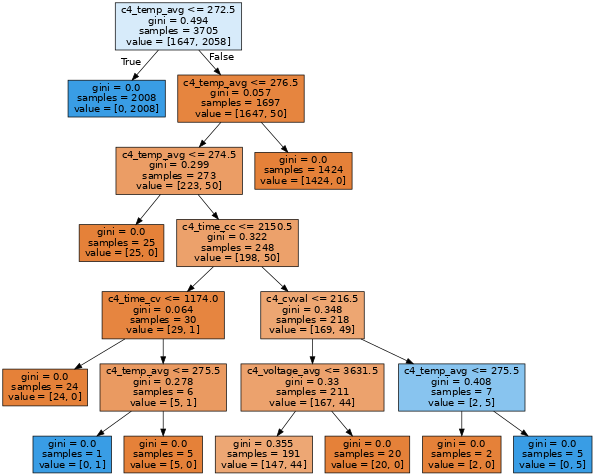

In [114]:
# Convert to png using system command (requires Graphviz)
from subprocess import call
call(['dot', '-Tpng', 'tree_normal.dot', '-o', 'tree_normal.png', '-Gdpi=50'])

# Display in jupyter notebook
from IPython.display import Image
Image(filename = 'tree_normal.png')

## 결론 도출  

### Feature Importance

In [115]:
df_importance = pd.DataFrame()
df_importance["Feature"] = v_feature_name
df_importance["importance"] = tree_normal.feature_importances_

In [116]:
# Importance 별로 정렬
df_importance.sort_values('importance', ascending = False, inplace = True)
df_importance.round(3)

,Feature,importance
6,c4_temp_avg,0.996
4,c4_cvval,0.002
5,c4_time_cc,0.001
1,c4_voltage_avg,0.001
3,c4_time_cv,0.000
0,c4_curr_end,0.000
2,c4_ccval,0.000


Text(0, 0.5, '변수')

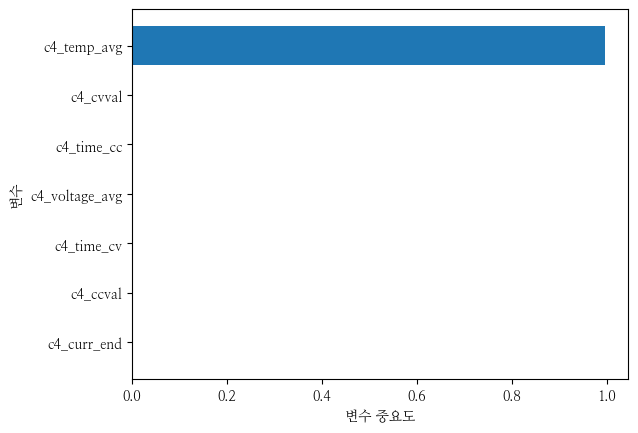

In [117]:
# 그래프 도식화
df_importance.sort_values('importance', ascending = True, inplace = True)
coordinates = range(len(df_importance))
plt.barh(y = coordinates, width = df_importance['importance'])
plt.yticks(coordinates, df_importance['Feature'])
plt.xlabel("변수 중요도")
plt.ylabel("변수")

* 중요 설명변수 : 트리 생성 시 000, 000 순으로 영향이 크다고 해석할 수 있다.  


* 단, 계산된 변수 중요도 값이 낮거나 0이더라도 선택되는 Train Data에 따라 중요도는 변경될 수 있다.  

# Cell 불량

## 데이터 불러오기 구성

In [157]:
df_process_group = pd.read_csv('/home/piai/바탕화면/df_process_group.csv', encoding = 'euc-kr')
df_process_group.drop(['box_col', 'box_dan'], axis=1, inplace=True)
df_process_group_x = df_process_group.drop(['judge'], axis=1, inplace=True)

AttributeError: 'NoneType' object has no attribute 'head'

## 모델 생성

In [147]:
random = 100
tree_normal = DecisionTreeClassifier(random_state = random)
tree_normal.fit(df_process_group_x, df_process_group_y)

# 정확도
print("Accuracy on train set : {:.3f}".format(tree_normal.score(df_process_group_x, df_process_group_y)))

Accuracy on train set : 0.987


### 시각화

In [153]:
# 나무구조 시각화(Graphviz)
v_feature_name = df_process_group.columns
export_graphviz(tree_normal, out_file="tree_normal.dot", feature_names = v_feature_name, impurity = True, filled = True)

# with open("tree_normal.dot") as f:
#     dot_graph = f.read()
# display(graphviz.Source(dot_graph))

ValueError: Length of feature_names, 5 does not match number of features, 4



In [149]:
# Convert to png using system command (requires Graphviz)
from subprocess import call
call(['dot', '-Tpng', 'tree_normal.dot', '-o', 'tree_normal.png', '-Gdpi=50'])

# Display in jupyter notebook
from IPython.display import Image
Image(filename = 'tree_normal.png')

## 결론 도출

In [123]:
df_importance = pd.DataFrame()
df_importance["Feature"] = v_feature_name
df_importance["importance"] = tree_normal.feature_importances_

In [124]:
# Importance 별로 정렬
df_importance.sort_values('importance', ascending = False, inplace = True)
df_importance.round(3)

,Feature,importance
35,c4_temp_avg,0.160
8,c2_curr_end,0.063
31,c4_ccval,0.049
2,c1_time_cc,0.049
0,c1_curr_end,0.047
34,c4_time_cc,0.045
21,c3_time_cv,0.044
33,c4_cvval,0.042
10,c2_ccval,0.042
32,c4_time_cv,0.041


Text(0, 0.5, '변수')

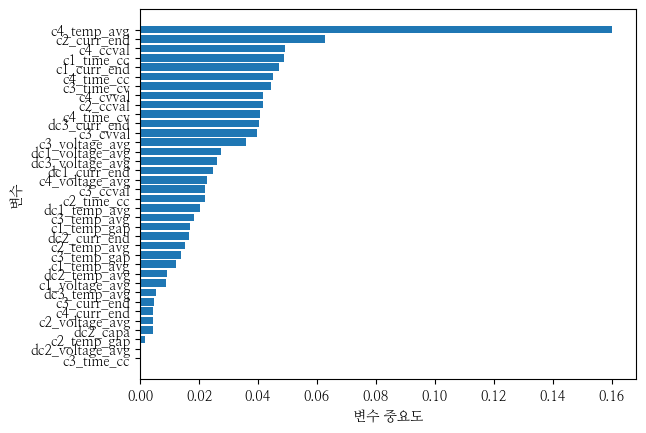

In [125]:
# 그래프 도식화
df_importance.sort_values('importance', ascending = True, inplace = True)
coordinates = range(len(df_importance))
plt.barh(y = coordinates, width = df_importance['importance'])
plt.yticks(coordinates, df_importance['Feature'])
plt.xlabel("변수 중요도")
plt.ylabel("변수")